# O conjunto corrigido: quanto do erro vinha dos rótulos?

As etapas 2 e 3 usaram o CIC-IDS2017 como publicado ([ADR 0001](../docs/adr/0001-versao-do-conjunto.md))
e acharam erros de rótulo no caminho: as respostas da vítima e uma varredura interna da máquina
invadida aparecem como tráfego normal. Engelen et al. refizeram o conjunto a partir das capturas,
com um extrator de fluxos consertado e rótulos novos. Este notebook repete os experimentos principais
nessa versão, pelo mesmo pipeline ([ADR 0010](../docs/adr/0010-conjunto-corrigido.md)), e compara
os resultados com os do original.

Na conversão, os fluxos **"Attempted"** (de ataque, mas sem conteúdo malicioso) viram normais, como
recomendam os autores, e a varredura feita pela máquina invadida vira **PortScan**.

**Como rodar:** depois de baixar e extrair `CICIDS2017_improved.zip` em
`data/external/cicids2017_improved/`, rode `nids data clean` e `nids data split` e os treinos com
`--config configs/data_improved.yaml` (`xgb_random`, `xgb_temporal`, `xgb_unseen`,
`iforest_unseen` e `ae_unseen`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from nids import schema
from nids.models.registry import load_model

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "reports" / "figures"
SOURCES = {"original": ROOT / "reports", "corrigido": ROOT / "reports" / "improved"}
DATA = {"original": ROOT / "data", "corrigido": ROOT / "data" / "improved"}
MODEL_DIRS = {"original": ROOT / "models", "corrigido": ROOT / "models" / "improved"}


def load_results(folder):
    results = {}
    for report in ("supervised", "anomaly"):
        results |= json.loads((folder / f"{report}.json").read_text(encoding="utf-8"))
    return results


RESULTS = {source: load_results(folder) for source, folder in SOURCES.items()}
SPLITS = {
    source: json.loads((folder / "splits.json").read_text(encoding="utf-8"))
    for source, folder in SOURCES.items()
}
MODELS = {
    "xgb_temporal": "XGBoost · P1 (já viu)",
    "xgb_unseen": "XGBoost · P2",
    "iforest_unseen": "Isolation Forest · P2",
    "ae_unseen": "Autoencoder · P2",
}
TEST_FAMILIES = ["PortScan", "DDoS", "Bot", "WebAttack", "Infiltration"]

# Posições 1 e 2 da paleta categórica: a cor segue o conjunto
COLORS = {"original": "#2a78d6", "corrigido": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "savefig.dpi": 110,
        "font.size": 9,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
    }
)
pd.set_option("display.max_columns", 20, "display.width", 140)


def fmt(value):
    return f"{value:,.0f}".replace(",", ".") if abs(value) > 1 else f"{value:.3f}"


def detection(source, name):
    return RESULTS[source][name]["detection"]["test"]

## 1. O que mudou nos rótulos

Primeiro, quantos fluxos de cada ataque são "Attempted" no conjunto corrigido, e como fica o teste
do P2 (quinta e sexta) nos dois conjuntos.

In [2]:
raw = ROOT / "data" / "external" / "cicids2017_improved"
labels = pd.concat(
    (pd.read_csv(path, usecols=["Label", "Attempted Category"]) for path in raw.glob("*.csv")),
    ignore_index=True,
)
attempted = labels["Attempted Category"] != -1
attack = labels["Label"].str.replace(" - Attempted", "", regex=False)
table = (
    pd.DataFrame({"ataque": attack[labels["Label"] != "BENIGN"], "attempted": attempted})
    .groupby("ataque")["attempted"]
    .agg(fluxos="size", attempted="sum")
)
table["% attempted"] = table["attempted"] / table["fluxos"]
display(table.sort_values("fluxos", ascending=False).map(fmt))

test = pd.DataFrame({source: SPLITS[source]["unseen"]["test"] for source in SOURCES}).fillna(0)
display(test.map(fmt))

,fluxos,attempted,% attempted
ataque,,,
Portscan,159.066,0.000,0.000
DoS Hulk,159.049,581,0.004
DDoS,95.144,0.000,0.000
Infiltration - Portscan,71.767,0.000,0.000
DoS GoldenEye,7.647,80,0.010
DoS Slowloris,5.706,1.847,0.324
DoS Slowhttptest,5.108,3.368,0.659
Botnet,4.803,4.067,0.847
FTP-Patator,3.984,12,0.003


,original,corrigido
BENIGN,764.202,504.627
WebAttack,2.143,104
Infiltration,36,31
Bot,1.953,736
PortScan,90.255,127.423
DDoS,128.012,95.144


**Leitura.** Em alguns ataques, a maior parte dos fluxos era só tentativa: são "Attempted" 97 % dos
de XSS, 95 % dos de força bruta web, 85 % dos de Bot e 66 % dos de DoS Slowhttptest. Como viram
tráfego normal, o teste do P2 fica com 104 fluxos de ataques web (eram 2.143) e 736 de Bot (eram
1.953). A varredura da máquina invadida, que no original estava como normal, entra como PortScan
de quinta-feira, e por isso o PortScan sobe para 127 mil fluxos. O conjunto inteiro também é menor
(1,8 milhão de fluxos limpos, contra 2,5 milhões), porque o extrator consertado monta os fluxos de
outro jeito.

## 2. A divisão aleatória ainda infla o resultado?

Na etapa 2, o mesmo XGBoost marcou 0,957 de macro-F1 com a divisão aleatória (P0) e 0,801 com a
temporal (P1). Abaixo, os dois protocolos nos dois conjuntos.

In [3]:
rows = {}
for source in SOURCES:
    for name, protocol in (("xgb_random", "P0"), ("xgb_temporal", "P1")):
        metrics = RESULTS[source][name]
        rows[(source, protocol)] = {
            "validação": metrics["val"]["macro_f1"],
            "teste": metrics["test"]["macro_f1"],
        }
table = pd.DataFrame(rows).T
display(table.map(fmt))
inflation = {
    source: table.loc[(source, "P0"), "teste"] - table.loc[(source, "P1"), "teste"]
    for source in SOURCES
}
print({source: round(100 * value, 1) for source, value in inflation.items()}, "pontos")

per_class = pd.DataFrame(
    {
        (source, name): {c: m["f1"] for c, m in RESULTS[source][name]["test"]["per_class"].items()}
        for source in SOURCES
        for name in ("xgb_random", "xgb_temporal")
    }
)
display(per_class.map(fmt))

validação  teste
original  P0     0.964  0.957
          P1     0.962  0.801
corrigido P0     0.992  0.997
          P1     1.000  0.997

{'original': np.float64(15.6), 'corrigido': np.float64(-0.0)} pontos


original               corrigido             
           xgb_random xgb_temporal xgb_random xgb_temporal
BENIGN          0.999        0.982      1.000        0.999
Bot             0.744        0.000      1.000        1.000
BruteForce      0.998        0.988      1.000        0.988
DDoS            1.000        0.808      1.000        0.999
DoS             0.998        0.983      1.000        0.994
PortScan        0.997        0.979      1.000        0.998
WebAttack       0.963        0.866      0.977        1.000

**Leitura.** No conjunto corrigido, a divisão aleatória e a temporal dão o mesmo resultado no teste
(0,997). Os 15,6 pontos de diferença do original vinham de erros nos dados, não da divisão em si: no
P1, o Bot sai de 0,000 para 1,000 e o DDoS, de 0,808 para 0,999. Na etapa 2, a queda do Bot foi
atribuída a uma mudança de comportamento depois da janela oficial do ataque, e a do DDoS, às
respostas da vítima rotuladas como normais. No corrigido, 85 % dos fluxos de Bot viraram
"Attempted", e as respostas quase somem (seção 4). A lição da etapa 2 continua de pé, por outro
motivo: a divisão aleatória espalha os fluxos errados pelos dois lados e esconde os defeitos; a
temporal os expõe.

## 3. A tabela-alvo nos dois conjuntos

Revocação por família no teste, com o limiar de 1 % de falsos positivos na validação. No conjunto
corrigido, o PortScan junta a varredura interna de quinta e a externa de sexta; a tabela abre as
duas.

In [4]:
def family_recall(source, name):
    per_family = detection(source, name)["per_family"]
    detected = sum(per_family[f]["detected"] for f in TEST_FAMILIES)
    total = sum(per_family[f]["support"] for f in TEST_FAMILIES)
    return {f: per_family[f]["recall"] for f in TEST_FAMILIES} | {"total": detected / total}


rows = {}
for name, label in MODELS.items():
    for source in SOURCES:
        d = detection(source, name)
        rows[(label, source)] = family_recall(source, name) | {
            "FPR no teste": d["fpr"],
            "PR-AUC": d["pr_auc"],
        }
target = pd.DataFrame(rows)
display(target.map(fmt))

XGBoost · P1 (já viu)           XGBoost · P2           Isolation Forest · P2           Autoencoder · P2          
                          original corrigido     original corrigido              original corrigido         original corrigido
PortScan                     0.999     1.000        0.010     0.015                 0.003     0.990            0.092     0.993
DDoS                         0.999     1.000        0.639     1.000                 0.000     0.000            0.254     0.100
Bot                          0.000     1.000        0.000     0.000                 0.008     0.000            0.003     0.058
WebAttack                    0.991     1.000        0.933     1.000                 0.000     0.000            0.000     0.000
Infiltration                 0.000     0.500        0.000     0.774                 0.750     0.226            0.722     0.839
total                        0.990     1.000        0.381     0.435                 0.001     0.565            0.184     0.609
FPR no teste                 0.039     0.009        0.021     0.015                 0.037     0.016            0.084     0.017
PR-AUC                       0.994     1.000        0.699     0.908                 0.410     0.850            0.540     0.927

In [5]:
# Scores no teste do P2 dos modelos do P2, para abrir o PortScan por dia e combinar XGBoost e
# autoencoder como na API
TEST = {
    source: pd.read_parquet(DATA[source] / "processed" / "unseen" / "test.parquet")
    for source in SOURCES
}
ALARMS = {}
for source, df in TEST.items():
    for name in ("xgb_unseen", "iforest_unseen", "ae_unseen"):
        model = load_model(MODEL_DIRS[source] / name)
        ALARMS[(source, name)] = model.score(df) > model.metadata["threshold"]
    ALARMS[(source, "união")] = ALARMS[(source, "xgb_unseen")] | ALARMS[(source, "ae_unseen")]

rows = {}
for source, df in TEST.items():
    family = df[schema.FAMILY].astype(str).to_numpy()
    day = df[schema.DAY].astype(str).to_numpy()
    groups = {
        "PortScan de quinta (varredura interna)": (family == "PortScan") & (day == "thursday"),
        "PortScan de sexta (varredura externa)": (family == "PortScan") & (day == "friday"),
        "todos os ataques": family != schema.BENIGN,
    }
    for name in ("xgb_unseen", "iforest_unseen", "ae_unseen", "união"):
        alarm = ALARMS[(source, name)]
        rows[(name, source)] = {
            g: (alarm & mask).sum() / mask.sum() if mask.any() else np.nan
            for g, mask in groups.items()
        } | {
            "FPR no teste": (alarm & (family == schema.BENIGN)).sum()
            / (family == schema.BENIGN).sum()
        }
display(pd.DataFrame(rows).map(lambda v: "—" if pd.isna(v) else fmt(v)))

,xgb_unseen,iforest_unseen,ae_unseen,união,xgb_unseen,iforest_unseen,ae_unseen,união
,original,original,original,original,corrigido,corrigido,corrigido,corrigido
PortScan de quinta (varredura interna),—,—,—,—,0.043,0.975,0.982,0.984
PortScan de sexta (varredura externa),0.010,0.003,0.092,0.100,0.002,0.998,0.998,1.000
todos os ataques,0.381,0.001,0.184,0.454,0.435,0.565,0.609,0.994
FPR no teste,0.021,0.037,0.084,0.093,0.015,0.016,0.017,0.030


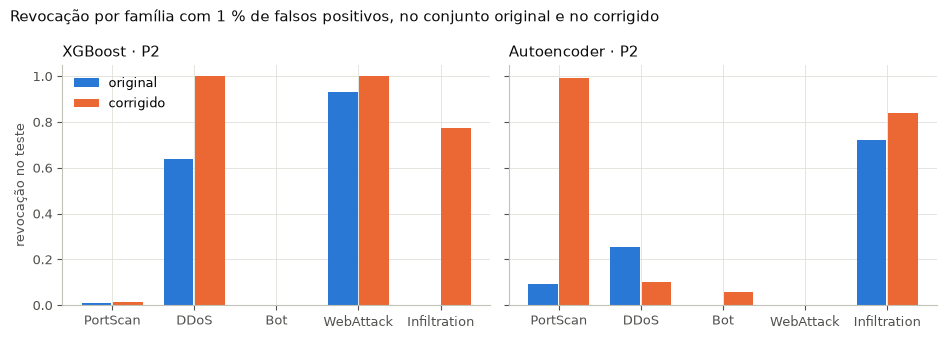

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
x = np.arange(len(TEST_FAMILIES))
for ax, name in zip(axes, ("xgb_unseen", "ae_unseen"), strict=True):
    for i, source in enumerate(SOURCES):
        values = [family_recall(source, name)[f] for f in TEST_FAMILIES]
        ax.bar(x + (i - 0.5) * 0.38, values, width=0.36, color=COLORS[source], label=source)
    ax.set_xticks(x, TEST_FAMILIES)
    ax.set_title(MODELS[name], loc="left", color=INK)
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("revocação no teste")
axes[0].legend(loc="upper left")
fig.suptitle(
    "Revocação por família com 1 % de falsos positivos, no conjunto original e no corrigido",
    x=0.01,
    ha="left",
    color=INK,
)
fig.tight_layout()
fig.savefig(FIGURES / "corrigido_revocacao.png", bbox_inches="tight")
plt.show()

**Leitura.** Diante dos ataques nunca vistos, o quadro muda bastante:

- O **XGBoost do P2** sobe de 38 % para 44 %. Ele pega todo o DDoS, os poucos ataques web que
  sobraram e 77 % da infiltração, mas o PortScan, que é 57 % dos ataques do teste, continua
  passando.
- Os **detectores de anomalia passam a pegar o PortScan**: 99 % no Isolation Forest e no
  autoencoder, nas duas varreduras, contra 0,3 % e 9 % no original. O autoencoder chega a 61 % no
  total.
- **Juntos, XGBoost e autoencoder detectam 99,4 % dos ataques**, com 3,0 % de falsos positivos no
  teste. O Bot é a única família que quase ninguém pega.
- O PR-AUC sobe em todos os modelos do P2, de 0,41–0,70 para 0,85–0,93.

Por que o PortScan ficou fácil para os detectores de anomalia? Uma sonda de varredura é um fluxo
minúsculo. Abaixo, a fração de fluxos com até 2 pacotes nos normais do treino e no PortScan do teste.

In [7]:
cols = ["total_fwd_packets", "total_backward_packets", "fin_flag_count", "rst_flag_count"]
rows = {}
for source in SOURCES:
    folder = DATA[source] / "processed" / "unseen"
    train = pd.read_parquet(folder / "train.parquet", columns=[*cols, schema.FAMILY])
    benign = train[train[schema.FAMILY] == schema.BENIGN]
    scan = TEST[source][TEST[source][schema.FAMILY] == "PortScan"]
    tiny = (benign.total_fwd_packets + benign.total_backward_packets) <= 2
    teardown = tiny & ((benign.fin_flag_count > 0) | (benign.rst_flag_count > 0))
    rows[source] = {
        "normais do treino com até 2 pacotes": tiny.mean(),
        "... e com FIN ou RST": teardown.mean(),
        "PortScan do teste com até 2 pacotes": (
            (scan.total_fwd_packets + scan.total_backward_packets) <= 2
        ).mean(),
    }
display(pd.DataFrame(rows).map(lambda v: f"{100 * v:.1f} %"))

,original,corrigido
normais do treino com até 2 pacotes,33.7 %,18.0 %
... e com FIN ou RST,0.7 %,0.8 %
PortScan do teste com até 2 pacotes,98.4 %,79.2 %


**Leitura.** O tráfego normal de treino do original tem quase o dobro de fluxos minúsculos (até 2
pacotes): 34 % contra 18 %. As sondas de varredura também mudam: 98 % são minúsculas no original e
79 % no corrigido. No original, o detector aprende que fluxo minúsculo é normal e deixa a varredura
passar; a forma como o extrator monta os fluxos muda o que parece normal. Uma explicação candidata
seriam os restos de conexão (pacotes FIN e RST depois do fim da conexão) que o extrator antigo
transformava em fluxos novos, descritos por Engelen et al. Mas os fluxos minúsculos com FIN ou RST
pesam o mesmo nos dois conjuntos (0,7 % e 0,8 %), então a diferença não vem deles; a origem exata
fica em aberto.

## 4. Os alarmes falsos

No original, a taxa de falsos positivos no teste passava do 1 % escolhido na validação (de 2 % a
8 %), e quase todo o excesso eram respostas da vítima e a varredura interna rotuladas como normais.
No corrigido, a varredura tem rótulo próprio. E as respostas?

In [8]:
def response_flows(source):
    # Fluxos normais cujo par de IPs é o inverso de um par de ataque do mesmo dia
    flows = pd.read_parquet(
        DATA[source] / "interim" / "flows.parquet",
        columns=[schema.DAY, "source_ip", "destination_ip", schema.FAMILY],
    )
    attacks = flows[flows[schema.FAMILY] != schema.BENIGN]
    pairs = set(
        zip(
            attacks[schema.DAY].astype(str),
            attacks["source_ip"],
            attacks["destination_ip"],
            strict=True,
        )
    )
    df = TEST[source]
    reverse = zip(df[schema.DAY].astype(str), df["destination_ip"], df["source_ip"], strict=True)
    responses = np.fromiter((pair in pairs for pair in reverse), bool, len(df))
    return responses & (df[schema.FAMILY] == schema.BENIGN).to_numpy()


rows = {}
for source in SOURCES:
    responses = response_flows(source)
    benign = (TEST[source][schema.FAMILY] == schema.BENIGN).to_numpy()
    for name in ("xgb_unseen", "iforest_unseen", "ae_unseen"):
        alarm = ALARMS[(source, name)]
        clean = benign & ~responses
        rows[(name, source)] = {
            "respostas rotuladas como normais": responses.sum(),
            "alarmes falsos": (alarm & benign).sum(),
            "em respostas": (alarm & responses).sum(),
            "FPR oficial": (alarm & benign).sum() / benign.sum(),
            "FPR sem as respostas": (alarm & clean).sum() / clean.sum(),
        }
display(pd.DataFrame(rows).map(fmt))

,xgb_unseen,iforest_unseen,ae_unseen,xgb_unseen,iforest_unseen,ae_unseen
,original,original,original,corrigido,corrigido,corrigido
respostas rotuladas como normais,35.103,35.103,35.103,2.429,2.429,2.429
alarmes falsos,15.817,28.370,64.272,7.611,8.083,8.653
em respostas,8.748,20.304,26.442,215,1.878,2.393
FPR oficial,0.021,0.037,0.084,0.015,0.016,0.017
FPR sem as respostas,0.010,0.011,0.052,0.015,0.012,0.012


**Leitura.** No corrigido, a taxa de falsos positivos no teste fica perto do 1 % escolhido na
validação (1,5 % a 1,7 %), e as respostas da vítima rotuladas como normais quase somem: 2.429 fluxos
no teste do P2, contra 35.103 no original. Lá, elas e a varredura explicavam quase todo o excesso de
alarmes; aqui, o pouco excesso que sobra (0,2 a 0,5 ponto) não vem delas. O limiar escolhido com o
tráfego de segunda a quarta vale na quinta e na sexta.

## 5. Conclusões

1. **A diferença entre a divisão aleatória e a temporal some no conjunto corrigido** (0,997 nas
   duas). Os 15,6 pontos do original vinham de erros nos dados, que a divisão aleatória escondia. A
   recomendação da etapa 2 continua valendo: é a divisão temporal que mostra os problemas.
2. **Com rótulos e fluxos corrigidos, a detecção de anomalias funciona.** O autoencoder sai de 18 %
   para 61 % de revocação nos ataques nunca vistos e, junto com o XGBoost, chega a 99,4 %, com 3 %
   de falsos positivos. O resultado pessimista da etapa 3 era, em boa parte, efeito dos defeitos do
   conjunto original, sobretudo na varredura de portas.
3. **O excesso de alarmes falsos do original era erro de rótulo:** no corrigido, a taxa de falsos
   positivos do teste fica perto da validação.
4. **O Bot continua difícil** para todos os modelos.
5. **A qualidade dos dados quase não aparece na divisão aleatória** (0,957 no original, 0,997 no
   corrigido), o que combina com Pekar e Jozsa (2024), que, segundo o resumo do artigo, viram um
   Random Forest manter desempenho alto nas várias versões corrigidas do CIC-IDS2017. É nos
   protocolos que medem generalização (temporal e ataques nunca vistos) que ela muda a conclusão.

**Ressalvas.** As diferenças misturam os rótulos refeitos e os fluxos montados de outro jeito, e não
dá para separar os dois efeitos com estes dados. Algumas famílias ficaram minúsculas (104 fluxos de
ataques web e 31 de infiltração no teste). E o conjunto continua sendo de laboratório, de 2017: a
próxima etapa testa os modelos em outra rede, a do CSE-CIC-IDS2018.